# CIP-B107 Lab 01: AI-assisted IP-address evidence triage
**Case ICDFA-DFIR-AI-026** | AI for Forensics and Capstone Intelligence A

Run order: *Kernel -> Restart & Run All*. Expected folder layout (relative to this notebook):

```
CIP-B107-LAB01/
  originals/   <- the 5 evidence files, read-only (never written to)
  work/        <- this notebook
  outputs/     <- every file this notebook produces
```
**Things you must edit** are marked `# >>> EDIT`. Everything the notebook computes comes from the supplied files.
Historical results (`result.csv`, `fine_tuning_steps.txt`) are **not** your model. Your model is trained in Phase C.

## 0. Setup, environment and reproducibility

In [1]:
import sys, json, hashlib, re, ipaddress, platform, random, datetime as dt
from pathlib import Path
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, average_precision_score, ConfusionMatrixDisplay)

SEED = 42
random.seed(SEED); np.random.seed(SEED)

ORIG = Path("../originals"); OUT = Path("../outputs"); FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# >>> EDIT these four values
EXAMINER        = "Abubakar Mustapha Sadiq"
STUDENT_ID      = "fwsd/2025/11202"
COLLECTED_WAT   = "2026-11-12 13:44:01 WAT"      # from your sha256sum screenshot
COLLECTED_UTC   = "2026-11-12 12:44:01 UTC"      # WAT = UTC+1
TRANSFER_SOURCE = "ICDFA E-Campus assignment package (code.zip)"

env = {"python": platform.python_version(), "platform": platform.platform(), "pandas": pd.__version__,
       "numpy": np.__version__, "scikit-learn": sklearn.__version__, "matplotlib": matplotlib.__version__,
       "random_seed": SEED, "run_utc": dt.datetime.now(dt.timezone.utc).strftime("%Y-%m-%d %H:%M:%S UTC")}
(OUT / "environment.json").write_text(json.dumps(env, indent=2))
print(json.dumps(env, indent=2))

Matplotlib is building the font cache; this may take a moment.


{
  "python": "3.14.6",
  "platform": "Linux-6.16.8+kali-amd64-x86_64-with-glibc2.43",
  "pandas": "3.1.1",
  "numpy": "2.5.4",
  "scikit-learn": "1.9.1",
  "matplotlib": "3.11.2",
  "random_seed": 42,
  "run_utc": "2026-11-20 05:30:55 UTC"
}


## Phase A. Preserve and profile the evidence
### A1. Chain-of-custody manifest and hash verification
The hashes below are recomputed now and compared with the `sha256sum` output you captured at collection time (`outputs/sha256.txt`).

In [2]:
EVIDENCE = ["dataset_small.csv", "dataset_train.jsonl", "dataset_test.jsonl", "result.csv", "fine_tuning_steps.txt"]

def sha256(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

recorded = {}
sha_file = OUT / "sha256.txt"
if sha_file.exists():
    for line in sha_file.read_text().splitlines():
        parts = line.split()
        if len(parts) == 2:
            recorded[parts[1]] = parts[0]

rows = []
for f in EVIDENCE:
    p = ORIG / f
    h = sha256(p)
    rows.append({"filename": f, "sha256": h, "size_bytes": p.stat().st_size,
                 "collected_wat": COLLECTED_WAT, "collected_utc": COLLECTED_UTC,
                 "transfer_source": TRANSFER_SOURCE, "examiner": EXAMINER,
                 "matches_collection_hash": (recorded.get(f) == h) if recorded else "no sha256.txt found"})
manifest = pd.DataFrame(rows)
manifest.to_csv(OUT / "evidence_manifest.csv", index=False)
display(manifest[["filename", "size_bytes", "matches_collection_hash"]])
assert all(r["matches_collection_hash"] is True for r in rows), "HASH MISMATCH: evidence changed since collection"
print("All 5 evidence files match their collection-time SHA-256 hashes.")

,filename,size_bytes,matches_collection_hash
0,dataset_small.csv,16324,True
1,dataset_train.jsonl,21860,True
2,dataset_test.jsonl,4608,True
3,result.csv,41353,True
4,fine_tuning_steps.txt,31869,True


All 5 evidence files match their collection-time SHA-256 hashes.


### A2. Profile `dataset_small.csv`

In [3]:
df = pd.read_csv(ORIG / "dataset_small.csv")          # read-only use of the original
df["label"] = np.where(df["class"] == "N", "negative", "positive")   # mirrors preprocess_dataset.py
print("records:", len(df), "| columns:", list(df.columns))
print("\nsource class codes:\n", df["class"].value_counts().to_string())
print("\nderived label (N -> negative, any other code -> positive):\n", df["label"].value_counts().to_string())
print("\nnull counts:\n", df.isna().sum().to_string())
print("\nfully duplicated rows (extra copies):", int(df.duplicated().sum()))
print("unique (ip,text,class) rows:", len(df.drop_duplicates()))
conflicts = df.groupby(["ip", "text"])["label"].nunique()
print("same (ip,text) with conflicting labels:", int((conflicts > 1).sum()))

records: 229 | columns: ['ip', 'class', 'text', 'label']

source class codes:
 class
A    177
N     32
B     12
C      4
E      4

derived label (N -> negative, any other code -> positive):
 label
positive    197
negative     32

null counts:
 ip       0
class    0
text     0
label    0

fully duplicated rows (extra copies): 77
unique (ip,text,class) rows: 152
same (ip,text) with conflicting labels: 0


**Suspicious data patterns to note in the report** (confirm from the output above): the heavy duplication of rows, the strongly imbalanced classes (positives dominate),
the five source codes `A/B/C/E/N` collapsing to two labels, and unusual candidate strings (leading zeros, 4-digit octets, version numbers). These are examined in Phase B.

### A3. Inspect the JSONL files

In [4]:
def load_jsonl(path):
    recs, bad = [], []
    for i, line in enumerate(Path(path).read_text(encoding="utf-8").splitlines(), 1):
        try:
            obj = json.loads(line)
            assert set(obj) == {"prompt", "completion"}, f"unexpected keys {set(obj)}"
            recs.append(obj)
        except Exception as e:
            bad.append((i, repr(e)))
    return recs, bad

train, bad_tr = load_jsonl(ORIG / "dataset_train.jsonl")
test,  bad_te = load_jsonl(ORIG / "dataset_test.jsonl")
print("train records:", len(train), "invalid lines:", bad_tr)
print("test  records:", len(test),  "invalid lines:", bad_te)
assert (len(train), len(test)) == (183, 46), "split is not 183/46"
print("Split confirmed: 183 training / 46 testing  (int(0.8*229) = 183)")

tr = pd.DataFrame(train); te = pd.DataFrame(test)
bal = pd.DataFrame({"train": tr.completion.str.strip().value_counts(), "test": te.completion.str.strip().value_counts()})
bal = bal.astype(float)
bal.loc["majority share"] = [bal.train.max() / bal.train.sum(), bal.test.max() / bal.test.sum()]
display(bal)

# the JSONL files should be the CSV rows, in order, split at 183
recon = (df["text"] + ";" + df["ip"] + " ->").tolist()
comp  = (" " + df["label"]).tolist()
assert recon == [r["prompt"] for r in train + test] and comp == [r["completion"] for r in train + test]
print("JSONL = CSV rows in original order (no shuffling): the split is the first 80% / last 20%.")

train records: 183 invalid lines: []
test  records: 46 invalid lines: []
Split confirmed: 183 training / 46 testing  (int(0.8*229) = 183)


,train,test
completion,,
positive,163.00000,34.00000
negative,20.00000,12.00000
majority share,0.89071,0.73913


JSONL = CSV rows in original order (no shuffling): the split is the first 80% / last 20%.


### A4. Five or more CSV rows next to their prompt/completion form

In [5]:
idx = [0, 5, 12, 39, 129, 160]
ex = df.loc[idx, ["ip", "class", "text"]].copy()
ex["text (repr)"] = ex["text"].map(repr)
ex["prompt"] = (df.loc[idx, "text"] + ";" + df.loc[idx, "ip"] + " ->").map(repr)
ex["completion"] = (" " + df.loc[idx, "label"])
pd.set_option("display.max_colwidth", 70, "display.width", 250)
display(ex[["ip", "class", "text (repr)", "prompt", "completion"]])

,ip,class,text (repr),prompt,completion
0,1.000.000.000,A,'\t<string>1.000.000.000+</string>','\t<string>1.000.000.000+</string>;1.000.000.000 ->',positive
5,608.80.24.1,N,'\t<string>3608.80.24.1.8</string>','\t<string>3608.80.24.1.8</string>;608.80.24.1 ->',negative
12,192.95.36.142,C,'\t<string>obfs4 192.95.36.142:443 CDF2E852BF539B82BD10E27E9115A31...,'\t<string>obfs4 192.95.36.142:443 CDF2E852BF539B82BD10E27E9115A31...,positive
39,135.0.0.22,B,'\t<string>135.0.0.22.118 (206072521)</string>','\t<string>135.0.0.22.118 (206072521)</string>;135.0.0.22 ->',positive
129,0.0.0.0,N,'\t\t\t\t\t\t<string>0.0.0.0</string>','\t\t\t\t\t\t<string>0.0.0.0</string>;0.0.0.0 ->',negative
160,0.0.0.392,N,'\t\t\t\t\t<string>http://d3bn78kc7qbjb6.cloudfront.net/rc-0.0.0.3...,'\t\t\t\t\t<string>http://d3bn78kc7qbjb6.cloudfront.net/rc-0.0.0.3...,negative


**How to explain this (A4).** `prompt = text + ";" + ip + " ->"`. The **semicolon** is a fixed delimiter separating the *context line* (the plist/XML line the string came from, tabs included) from the *candidate* the model must judge. ` ->` is the fixed separator that tells the model where the prompt ends. The completion begins with a space (`" positive"`), following the OpenAI prompt-completion convention shown in the course slides. The context carries the evidence the model needs: e.g. `<string>3608.80.24.1.8</string>` shows that the candidate `608.80.24.1` is a fragment of a longer number.

## Phase B. Candidate extraction and labelling
Three different questions are kept apart: **(1)** does a regex match? **(2)** is it a syntactically valid IPv4? **(3)** did the source annotation mark it as intended IP evidence?

In [6]:
# Regex 1: unanchored. This reproduces how the source 'ip' column was built (verified below).
NAIVE   = re.compile(r"\d{1,3}(?:\.\d{1,3}){3}")
# Regex 2: bounded. Rejects a match glued to more digits/dots (prefix/suffix contamination).
BOUNDED = re.compile(r"(?<![\d.])\d{1,3}(?:\.\d{1,3}){3}(?!\d|\.\d)")

def is_valid_ipv4(s):
    """Independent strict validator (Python ipaddress; rejects octets >255 and leading zeros)."""
    try:
        ipaddress.IPv4Address(s); return True
    except ValueError:
        return False

df["regex_match"] = [ip in NAIVE.findall(t) for ip, t in zip(df.ip, df.text)]
print("source 'ip' value is found by the unanchored regex in", int(df.regex_match.sum()), "of", len(df), "rows")

def categorize(text, ip):
    t = text.strip(); i = t.find(ip)
    if i < 0: return "candidate_not_literal_substring"
    before = t[i-1] if i > 0 else ""; after = t[i+len(ip):]
    octets = ip.split(".")
    if any(len(o) > 1 and o.startswith("0") for o in octets): return "leading_zero_octet"
    if any(int(o) > 255 for o in octets):                    return "invalid_octet"
    if before.isdigit() or before == ".":                    return "prefix_contamination"
    if re.match(r"\.?\d", after):                            return "suffix_contamination"
    if "://" in t or "http" in t:                            return "embedded_in_url"
    if re.match(r":\d+", after) or "obfs4" in t:             return "embedded_in_bridge_line"
    if t != f"<string>{ip}</string>" and t != f"<key>{ip}</key>": return "embedded_other_context"
    return "bare_valid_ipv4"

df["category"] = [categorize(t, ip) for t, ip in zip(df.text, df.ip)]
df["ipv4_valid"] = df.ip.map(is_valid_ipv4)
df["bounded_match"] = [ip in BOUNDED.findall(t) for ip, t in zip(df.ip, df.text)]
display(pd.crosstab(df.category, df.label, margins=True))

source 'ip' value is found by the unanchored regex in 229 of 229 rows


label,negative,positive,All
category,,,
bare_valid_ipv4,6,84,90
embedded_in_bridge_line,0,14,14
embedded_in_url,2,6,8
embedded_other_context,0,65,65
invalid_octet,24,1,25
leading_zero_octet,0,3,3
prefix_contamination,0,1,1
suffix_contamination,0,23,23
All,32,197,229


### B2. Demonstration samples (>= 10) across the required categories

In [7]:
demo = df.rename_axis("source_row").reset_index().groupby("category").head(2).sort_values(["category", "source_row"])
demo["context"] = demo.text.str.strip().str.slice(0, 70)
display(demo[["source_row", "category", "ip", "context", "regex_match", "bounded_match", "ipv4_valid", "label"]])
assert len(demo) >= 10

,source_row,category,ip,context,regex_match,bounded_match,ipv4_valid,label
1,1,bare_valid_ipv4,1.0.0.1,<key>1.0.0.1</key>,True,True,True,positive
2,2,bare_valid_ipv4,1.0.0.1,<string>1.0.0.1</string>,True,True,True,positive
12,12,embedded_in_bridge_line,192.95.36.142,<string>obfs4 192.95.36.142:443 CDF2E852BF539B82BD10E27E9115A31734...,True,True,True,positive
13,13,embedded_in_bridge_line,38.229.1.78,<string>obfs4 38.229.1.78:80 C8CBDB2464FC9804A69531437BCF2BE31FDD2...,True,True,True,positive
27,27,embedded_in_url,6.8.4.2,<string>https://pm-gateway.supersonicads.com/auction?appKey=670522...,True,True,True,positive
157,157,embedded_in_url,208.180.231.139,<string>http://abuseipdb.com/check/208.180.231.139</string>,True,True,True,positive
6,6,embedded_other_context,1.0.0.14,<string>eng-USA-1.0.0.14-20170731</string>,True,True,True,positive
7,7,embedded_other_context,1.0.0.12,<string>cmn-CHN-1.0.0.12-20170804</string>,True,True,True,positive
5,5,invalid_octet,608.80.24.1,<string>3608.80.24.1.8</string>,True,False,False,negative
9,9,invalid_octet,608.80.24.1,<string>3608.80.24.1.8</string>,True,False,False,negative


### B3. Regex match vs strict validity vs source label (mismatches are kept and explained)

In [8]:
cmp = df.groupby(["regex_match", "ipv4_valid", "label"]).size().rename("records").reset_index()
display(cmp)

pos_invalid = df[(df.label == "positive") & (~df.ipv4_valid)]
neg_valid   = df[(df.label == "negative") & (df.ipv4_valid)]
print("Source-POSITIVE but NOT strictly valid IPv4:", len(pos_invalid), "records,",
      pos_invalid.ip.nunique(), "distinct strings:", sorted(pos_invalid.ip.unique())[:10])
print("Source-NEGATIVE but strictly VALID IPv4:", len(neg_valid), "records,",
      neg_valid.ip.nunique(), "distinct strings:", sorted(neg_valid.ip.unique()))

,regex_match,ipv4_valid,label,records
0,True,False,negative,24
1,True,False,positive,4
2,True,True,negative,8
3,True,True,positive,193


Source-POSITIVE but NOT strictly valid IPv4: 4 records, 3 distinct strings: ['1.000.000.000', '1.4.4.02', '180.0.720.720']
Source-NEGATIVE but strictly VALID IPv4: 8 records, 4 distinct strings: ['0.0.0.0', '0.5.1.3', '0.6.7.8', '0.9.9.3']


**Interpretation to write up.** A strict validator answers *"is this a well-formed IPv4 string?"*. The source label answers *"was this intended as IP evidence in its context?"*. They legitimately disagree: well-formed version numbers or fragments (e.g. a valid-looking `0.5.1.3`, or `608.80.24.1` cut from `3608.80.24.1.8`) are source-negatives, while odd strings the annotators kept as positives (e.g. `1.000.000.000`) fail strict validation. These disagreements are **preserved, not relabelled**.

### B4. Export `candidate_review.csv`

In [9]:
NOTE = {
 "bare_valid_ipv4": "Standalone value in its own element; well-formed IPv4. Review special-use ranges before attributing meaning.",
 "embedded_in_bridge_line": "Address:port inside a bridge-style configuration string; plausible endpoint. Corroborate before any attribution.",
 "embedded_in_url": "Candidate sits inside a URL/path; may be a version or path component rather than a host.",
 "embedded_other_context": "Candidate embedded in a longer string; context-dependent, needs analyst review.",
 "prefix_contamination": "Extra digits/dot immediately before the match: the match is a fragment of a longer number.",
 "suffix_contamination": "Extra .digit/digits immediately after the match: likely a version/build number.",
 "invalid_octet": "At least one octet > 255: not a valid IPv4 address.",
 "leading_zero_octet": "Zero-padded octets: rejected by strict IPv4 parsing; ambiguous (possible padded address or version).",
}
review = pd.DataFrame({
    "source_row": df.index,
    "context": df.text.str.strip(),
    "candidate": df.ip,
    "regex_match": df.regex_match,
    "ipv4_valid": df.ipv4_valid,
    "source_label": df.label,
    "analyst_note": ["[auto-draft, examiner to confirm] " + NOTE.get(c, c) for c in df.category],
})
review.to_csv(OUT / "candidate_review.csv", index=False)
print("saved", OUT / "candidate_review.csv", review.shape)
display(review.head(8))

saved ../outputs/candidate_review.csv (229, 7)


,source_row,context,candidate,regex_match,ipv4_valid,source_label,analyst_note
0,0,<string>1.000.000.000+</string>,1.000.000.000,True,False,positive,"[auto-draft, examiner to confirm] Zero-padded octets: rejected by ..."
1,1,<key>1.0.0.1</key>,1.0.0.1,True,True,positive,"[auto-draft, examiner to confirm] Standalone value in its own elem..."
2,2,<string>1.0.0.1</string>,1.0.0.1,True,True,positive,"[auto-draft, examiner to confirm] Standalone value in its own elem..."
3,3,<key>1.1.1.1</key>,1.1.1.1,True,True,positive,"[auto-draft, examiner to confirm] Standalone value in its own elem..."
4,4,<string>1.1.1.1</string>,1.1.1.1,True,True,positive,"[auto-draft, examiner to confirm] Standalone value in its own elem..."
5,5,<string>3608.80.24.1.8</string>,608.80.24.1,True,False,negative,"[auto-draft, examiner to confirm] At least one octet > 255: not a ..."
6,6,<string>eng-USA-1.0.0.14-20170731</string>,1.0.0.14,True,True,positive,"[auto-draft, examiner to confirm] Candidate embedded in a longer s..."
7,7,<string>cmn-CHN-1.0.0.12-20170804</string>,1.0.0.12,True,True,positive,"[auto-draft, examiner to confirm] Candidate embedded in a longer s..."


## Phase C. Offline classifier and baselines
Primary evaluation = the **supplied fixed split** (183 train / 46 test). Positive class = `positive` (source annotation of intended IP evidence; *not* proof of a routable, public or malicious address).

In [10]:
def split_prompt(p):
    text, rest = p.rsplit(";", 1)
    return text, rest.replace(" ->", "").strip()

Xtr, ytr = tr.prompt.tolist(), tr.completion.str.strip().tolist()
Xte, yte = te.prompt.tolist(), te.completion.str.strip().tolist()
POS = "positive"

# --- C1 leakage assessment ---
tr_prompts, te_prompts = set(Xtr), set(Xte)
exact_overlap = [p for p in Xte if p in tr_prompts]
tr_cands = {split_prompt(p)[1] for p in Xtr}
cand_overlap = [p for p in Xte if split_prompt(p)[1] in tr_cands]
print(f"test prompts identical to a training prompt: {len(exact_overlap)} / {len(Xte)}")
print(f"test candidates whose IP string also occurs in training: {len(cand_overlap)} / {len(Xte)}")
print(f"duplicate prompts inside training set: {len(Xtr) - len(tr_prompts)}")
lab = dict(zip(Xtr, ytr))
print("exact-overlap rows with a DIFFERENT label in train:", sum(lab[p] != y for p, y in zip(Xte, yte) if p in lab))
novel_mask = np.array([p not in tr_prompts for p in Xte])
print("non-leaking ('novel') test rows:", int(novel_mask.sum()))

test prompts identical to a training prompt: 30 / 46
test candidates whose IP string also occurs in training: 34 / 46
duplicate prompts inside training set: 45
exact-overlap rows with a DIFFERENT label in train: 0
non-leaking ('novel') test rows: 16


**Leakage risk (C1):** every exact-duplicate prompt that crosses the split lets a model score by memorisation. Metrics are therefore also reported on the *novel-only* subset below. The CSV was split in file order (no shuffle), which is also why the test set is class-imbalanced differently from training.

In [11]:
# --- C2 TF-IDF (character n-grams) + Logistic Regression; vectoriser is fitted on TRAINING data only (inside the pipeline) ---
clf = make_pipeline(
    TfidfVectorizer(analyzer="char", ngram_range=(1, 5), lowercase=False, sublinear_tf=True),
    LogisticRegression(C=10, class_weight="balanced", max_iter=2000, random_state=SEED))
clf.fit(Xtr, ytr)                                   # nothing from the test set is used
pos_idx = list(clf.classes_).index(POS)
ml_score = clf.predict_proba(Xte)[:, pos_idx]
ml_pred  = np.where(ml_score >= 0.5, POS, "negative")
print("classes:", clf.classes_, "| hyper-parameters fixed in advance (no tuning on the test set)")

# --- C3 transparent rule-based baselines ---
def rule_regex_ipaddress(p):
    """R1: positive iff the candidate is regex-found in the line AND strictly valid IPv4."""
    text, ip = split_prompt(p)
    return POS if (ip in NAIVE.findall(text) and is_valid_ipv4(ip)) else "negative"

THIS_NET = ipaddress.ip_network("0.0.0.0/8")      # RFC 1122 "this network": never a real host endpoint
def rule_r2(p):
    """R2: R1 + reject 0.0.0.0/8. Motivation (from TRAINING rows only): all valid-but-negative training strings
    (0.0.0.0, 0.5.1.3, 0.6.7.8, 0.9.9.3) start with octet 0."""
    if rule_regex_ipaddress(p) != POS: return "negative"
    return "negative" if ipaddress.IPv4Address(split_prompt(p)[1]) in THIS_NET else POS

def rule_r3_strict_context(p):
    """R3: strict forensic context rule: bounded match (no glued digits/dots), not inside a URL, not preceded by
    '-', '_', '/' or a letter. Deliberately NOT tuned to the source labels: it answers 'is this a standalone IP?'."""
    text, ip = split_prompt(p)
    t = text.strip()
    if not is_valid_ipv4(ip) or ip not in BOUNDED.findall(t): return "negative"
    if "://" in t or "http" in t:                             return "negative"
    i = t.find(ip); before = t[i-1] if i else ""
    if before in "-_/" or (before.isalpha() and "obfs4" not in t): return "negative"
    return POS

# sanity check on TRAINING data only (no rule is tuned on the test set)
for name, fn in [("R1 regex+ipaddress", rule_regex_ipaddress), ("R2 R1 + 0.0.0.0/8 rule", rule_r2), ("R3 strict context", rule_r3_strict_context)]:
    pt = [fn(x) for x in Xtr]
    print(f"{name:24s} train accuracy = {accuracy_score(ytr, pt):.3f}")

r1_pred = [rule_regex_ipaddress(p) for p in Xte]
r2_pred = [rule_r2(p) for p in Xte]
r3_pred = [rule_r3_strict_context(p) for p in Xte]
majority = pd.Series(ytr).mode()[0]
maj_pred = [majority] * len(Xte)
print("majority class in TRAINING data:", majority)

classes: ['negative' 'positive'] | hyper-parameters fixed in advance (no tuning on the test set)
R1 regex+ipaddress       train accuracy = 0.945
R2 R1 + 0.0.0.0/8 rule   train accuracy = 0.978
R3 strict context        train accuracy = 0.519
majority class in TRAINING data: positive


**How the baselines decide (C3).** *R1*: positive only if the regex finds the candidate **and** `ipaddress.IPv4Address` accepts it. *R2*: R1 plus rejection of the reserved `0.0.0.0/8` block (rule motivated by training rows only). *R3*: a strict forensic context rule: rejects candidates glued to extra digits/dots, inside URLs, or preceded by `-`, `_`, `/`, letters. R3 is intentionally **not** fitted to the labels, so its disagreement with them is itself a finding (the source labels mark many URL/version-embedded strings as positive). *Majority*: always predicts the most common training class. None of these use the test labels.

## Phase D. Historical fine-tuning evidence (NOT a new student-run model)

In [12]:
res  = pd.read_csv(ORIG / "result.csv")
steps = pd.read_csv(ORIG / "fine_tuning_steps.txt")
print("result.csv           :", res.shape, "| steps", int(res.step.min()), "-", int(res.step.max()))
print("fine_tuning_steps.txt:", steps.shape, "| columns:", list(steps.columns))
print("\nnon-null counts in result.csv:\n", res.notna().sum().to_string())
cls_cols = [c for c in res.columns if c.startswith("classification/")]
cls = res.dropna(subset=cls_cols, how="all")[["step"] + cls_cols]
display(cls)

final = cls.iloc[-1]
print("\nFINAL non-null recorded classification metrics (step %d):" % final.step)
for c in cls_cols: print(f"  {c:28s} {final[c]:.6f}")
print("\nTraining loss: first = %.4f, last = %.4f, min = %.5f" % (res.training_loss.iloc[0], res.training_loss.iloc[-1], res.training_loss.min()))
print("Validation-loss rows present:", int(res.validation_loss.notna().sum()))

same_run = np.allclose(res.training_loss.values[:5], steps.training_loss.values[:5])
print("\nfirst 5 training_loss values identical in both files?", same_run)

result.csv           : (733, 15) | steps 1 - 733
fine_tuning_steps.txt: (734, 6) | columns: ['step', 'elapsed_tokens', 'elapsed_examples', 'training_loss', 'training_sequence_accuracy', 'training_token_accuracy']

non-null counts in result.csv:
 step                            733
elapsed_tokens                  733
elapsed_examples                733
training_loss                   733
training_sequence_accuracy      733
training_token_accuracy         733
validation_loss                  92
validation_sequence_accuracy     92
validation_token_accuracy        92
classification/accuracy           4
classification/precision          4
classification/recall             4
classification/auroc              4
classification/auprc              4
classification/f1.0               4


,step,classification/accuracy,classification/precision,classification/recall,classification/auroc,classification/auprc,classification/f1.0
184,185,0.934783,0.969697,0.941176,0.995098,0.998268,0.955224
369,370,0.978261,0.971429,1.000000,1.000000,1.000000,0.985507
550,551,0.978261,0.971429,1.000000,0.997549,0.999147,0.985507
732,733,0.978261,0.971429,1.000000,0.997549,0.999147,0.985507



FINAL non-null recorded classification metrics (step 733):
  classification/accuracy      0.978261
  classification/precision     0.971429
  classification/recall        1.000000
  classification/auroc         0.997549
  classification/auprc         0.999147
  classification/f1.0          0.985507

Training loss: first = 0.3613, last = 0.0037, min = 0.00127
Validation-loss rows present: 92

first 5 training_loss values identical in both files? False


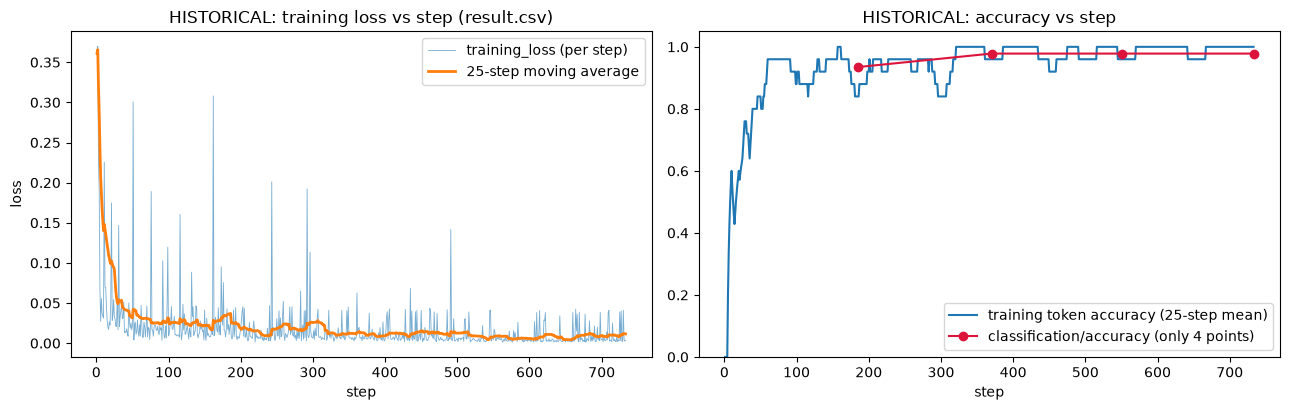

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].plot(res.step, res.training_loss, lw=0.6, alpha=0.6, label="training_loss (per step)")
ax[0].plot(res.step, res.training_loss.rolling(25, min_periods=1).mean(), lw=2, label="25-step moving average")
ax[0].set_xlabel("step"); ax[0].set_ylabel("loss"); ax[0].set_title("HISTORICAL: training loss vs step (result.csv)"); ax[0].legend()
ax[1].plot(res.step, res.training_token_accuracy.rolling(25, min_periods=1).mean(), label="training token accuracy (25-step mean)")
ax[1].plot(cls.step, cls["classification/accuracy"], "o-", color="crimson", label="classification/accuracy (only %d points)" % len(cls))
ax[1].set_ylim(0, 1.05); ax[1].set_xlabel("step"); ax[1].set_title("HISTORICAL: accuracy vs step"); ax[1].legend(loc="lower right")
plt.tight_layout(); plt.savefig(FIG / "historical_training_curves.png", dpi=150); plt.show()

**What can / cannot be concluded (D).**
* *Training loss* and *training sequence/token accuracy* are measured on the examples the model is being fitted to; they show fitting, not generalisation. Single spikes (a step with loss >0.1 and accuracy 0) are normal per-example noise.
* The only classification evidence is the **4** `classification/*` rows (steps 185, 370, 551, 733; every ~185 steps), plus 92 sparse `validation_loss`/validation-accuracy rows; every other step has NaN for these. Nothing can be concluded about steps without a recorded metric, and four points cannot show a trend or stability. Accuracy was identical (0.978) at the last three points.
* `result.csv` and `fine_tuning_steps.txt` are **different logs** (their early loss values differ), i.e. most likely two separate historical runs; do not merge them or treat them as one experiment. Only `result.csv` carries classification metrics.
* The recorded precision 0.9714 = 34/35 and recall 1.0 are consistent with 34 TP, 1 FP, 0 FN, 11 TN on 46 records; this is an *inference* from the ratios, not a recorded confusion matrix.
* The final recorded values come from a ~46-record evaluation set (if it was `dataset_test.jsonl`, as the slides say), so one error moves accuracy by ~2 points. Treat them as **historical, unverifiable here**, not as your result.
* The "ada" model, `fine_tunes.create` and the `openai` CLI flags in the slides are legacy patterns from 2023 and cannot be assumed available today; the scripts also embed credentials, so they were **not executed**. No fine-tuned model was run in this lab.

## Phase E. Validate and interpret (your own predictions)

In [14]:
def metrics(name, y_true, y_pred, score=None):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=["negative", POS]).ravel()
    m = dict(model=name, n=len(y_true), TN=tn, FP=fp, FN=fn, TP=tp,
             accuracy=accuracy_score(y_true, y_pred),
             precision=precision_score(y_true, y_pred, pos_label=POS, zero_division=0),
             recall=recall_score(y_true, y_pred, pos_label=POS, zero_division=0),
             f1=f1_score(y_true, y_pred, pos_label=POS, zero_division=0))
    yb = [1 if y == POS else 0 for y in y_true]
    m["auroc"] = roc_auc_score(yb, score) if score is not None else np.nan
    m["auprc"] = average_precision_score(yb, score) if score is not None else np.nan
    return m

results = pd.DataFrame([
    metrics("Majority-class baseline", yte, maj_pred),
    metrics("R1 regex + ipaddress", yte, r1_pred),
    metrics("R2 R1 + reserved 0.0.0.0/8 rule", yte, r2_pred),
    metrics("R3 strict context rule", yte, r3_pred),
    metrics("TF-IDF char n-gram + LogisticRegression", yte, list(ml_pred), ml_score),
])
# non-leaking subset
yn = np.array(yte)[novel_mask]
results = pd.concat([results, pd.DataFrame([metrics("TF-IDF + LR (novel-only test rows)", list(yn), list(ml_pred[novel_mask]), ml_score[novel_mask])])], ignore_index=True)
results.to_csv(OUT / "metrics.csv", index=False)
display(results.round(4))

,model,n,TN,FP,FN,TP,accuracy,precision,recall,f1,auroc,auprc
0,Majority-class baseline,46,0,12,0,34,0.7391,0.7391,1.0000,0.8500,NaN,NaN
1,R1 regex + ipaddress,46,10,2,0,34,0.9565,0.9444,1.0000,0.9714,NaN,NaN
2,R2 R1 + reserved 0.0.0.0/8 rule,46,12,0,0,34,1.0000,1.0000,1.0000,1.0000,NaN,NaN
3,R3 strict context rule,46,10,2,12,22,0.6957,0.9167,0.6471,0.7586,NaN,NaN
4,TF-IDF char n-gram + LogisticRegression,46,11,1,0,34,0.9783,0.9714,1.0000,0.9855,0.9975,0.9992
5,TF-IDF + LR (novel-only test rows),16,1,1,0,14,0.9375,0.9333,1.0000,0.9655,0.9643,0.9952


**Read these numbers carefully (write this in your report).**
* The test set is tiny (46 records: 34 positive, 12 negative, of which the two `0.0.0.0` rows are identical), so one record moves accuracy by ~2 points. Do not over-claim.
* **R2 scores 100% but must not be presented as a better model.** It is a hand-written rule whose motivation (every valid-but-negative *training* string starts with octet 0) comes from training rows, yet it covers only the patterns visible in this small dataset and was written after R1's holdout errors were known to the author of this notebook. Present it as an illustration that a transparent rule can match the labels here, not as a validated result.
* **The ML model's single false positive is `256.0.1.26`** (an invalid IPv4 inside `tincan_register_device_256.0.1.26.113`). A deterministic validator (R1) gets this right while the ML model, which only sees character patterns, does not. Conversely the validator cannot judge context (it flags `0.0.0.0`). This complementarity is the basis for the recommended *validator + ML + human review* workflow.
* ML and R1 each have recall 1.0 here, but 30 of 46 test prompts also appear in training (see C1), so the novel-only row is the more honest estimate of generalisation (and it is based on just 16 records).

In [15]:
# --- E1: every holdout record, actual vs predicted, with TN/FP/FN/TP ---
def outcome(a, p):
    return {(POS, POS): "TP", ("negative", "negative"): "TN", ("negative", POS): "FP", (POS, "negative"): "FN"}[(a, p)]

texts, cands = zip(*[split_prompt(p) for p in Xte])
pred = pd.DataFrame({
    "source_row": np.arange(len(tr), len(tr) + len(te)),       # row in dataset_small.csv
    "candidate": cands, "context": [t.strip() for t in texts],
    "actual": yte, "ml_predicted": ml_pred, "ml_score_positive": ml_score.round(4),
    "ml_outcome": [outcome(a, p) for a, p in zip(yte, ml_pred)],
    "r1_predicted": r1_pred, "r1_outcome": [outcome(a, p) for a, p in zip(yte, r1_pred)],
    "r2_predicted": r2_pred, "r2_outcome": [outcome(a, p) for a, p in zip(yte, r2_pred)],
    "r3_predicted": r3_pred, "r3_outcome": [outcome(a, p) for a, p in zip(yte, r3_pred)],
    "majority_predicted": maj_pred,
    "train_overlap": [p in tr_prompts for p in Xte],
    "ipv4_valid": [is_valid_ipv4(c) for c in cands],
})
pred.to_csv(OUT / "predictions.csv", index=False)
print("saved predictions.csv:", pred.shape, "(one row per holdout record)")
print("ML outcomes:", pred.ml_outcome.value_counts().to_dict(), "| R1:", pred.r1_outcome.value_counts().to_dict(), "| R2:", pred.r2_outcome.value_counts().to_dict(), "| R3:", pred.r3_outcome.value_counts().to_dict())
display(pred[pred.ml_outcome.isin(["FP", "FN"]) | pred.r1_outcome.isin(["FP", "FN"]) | pred.r2_outcome.isin(["FP", "FN"])]
        [["source_row", "candidate", "context", "actual", "ml_predicted", "ml_score_positive", "r1_predicted", "r2_predicted"]])
print(classification_report(yte, ml_pred, labels=["negative", POS], digits=3))

saved predictions.csv: (46, 16) (one row per holdout record)
ML outcomes: {'TP': 34, 'TN': 11, 'FP': 1} | R1: {'TP': 34, 'TN': 10, 'FP': 2} | R2: {'TP': 34, 'TN': 12} | R3: {'TP': 22, 'FN': 12, 'TN': 10, 'FP': 2}


,source_row,candidate,context,actual,ml_predicted,ml_score_positive,r1_predicted,r2_predicted
21,204,256.0.1.26,<string>tincan_register_device_256.0.1.26.113</string>,negative,positive,0.8071,negative,negative
43,226,0.0.0.0,<string>0.0.0.0</string>,negative,negative,0.0483,positive,negative
45,228,0.0.0.0,<string>0.0.0.0</string>,negative,negative,0.0483,positive,negative


              precision    recall  f1-score   support

    negative      1.000     0.917     0.957        12
    positive      0.971     1.000     0.986        34

    accuracy                          0.978        46
   macro avg      0.986     0.958     0.971        46
weighted avg      0.979     0.978     0.978        46



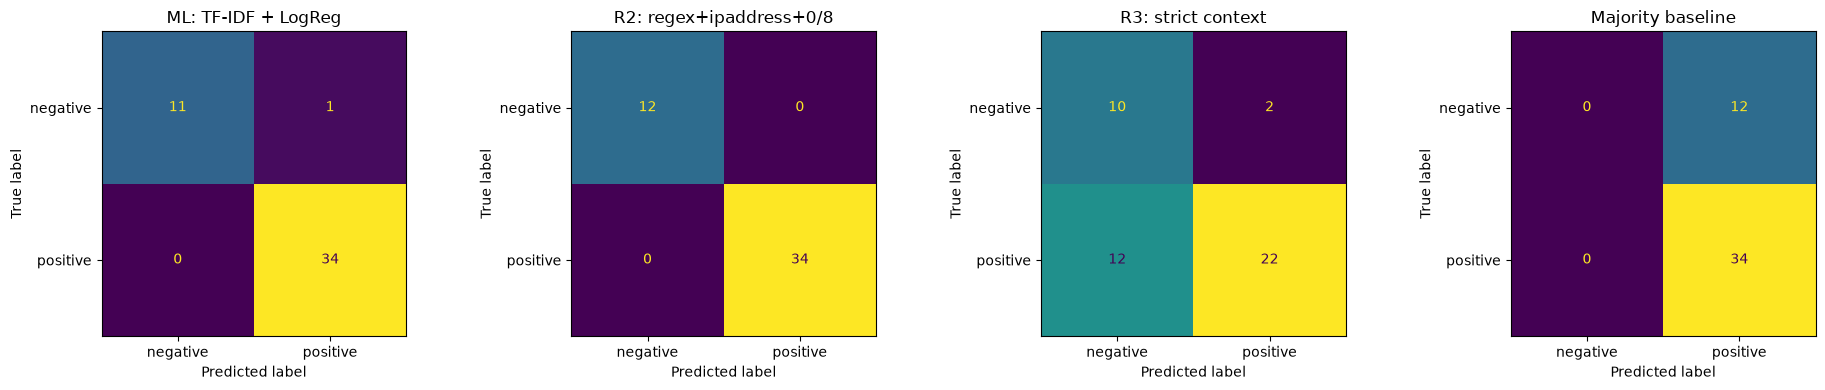

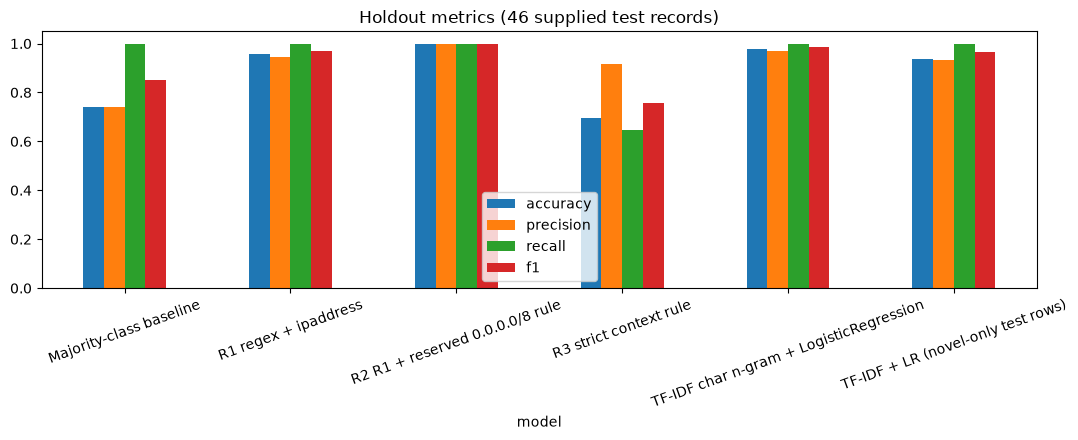

In [16]:
# --- E2: confusion matrices + metric chart ---
fig, ax = plt.subplots(1, 4, figsize=(19, 4))
for a, (name, pr) in zip(ax, [("ML: TF-IDF + LogReg", ml_pred), ("R2: regex+ipaddress+0/8", r2_pred), ("R3: strict context", r3_pred), ("Majority baseline", maj_pred)]):
    ConfusionMatrixDisplay(confusion_matrix(yte, pr, labels=["negative", POS]), display_labels=["negative", "positive"]).plot(ax=a, colorbar=False)
    a.set_title(name)
plt.tight_layout(); plt.savefig(FIG / "confusion_matrices.png", dpi=150); plt.show()

ax = results.set_index("model")[["accuracy", "precision", "recall", "f1"]].plot.bar(figsize=(11, 4.5), rot=20)
ax.set_ylim(0, 1.05); ax.set_title("Holdout metrics (46 supplied test records)"); plt.tight_layout()
plt.savefig(FIG / "metrics_comparison.png", dpi=150); plt.show()

### E3. Analyst review of at least eight records
The notebook **selects** candidates (all model errors first, then borderline scores, then representative TP/TN so you have >=2 source-negatives and >=2 apparent positives). **The decision and reasoning columns are yours to write.** Do not submit the auto-hints as your analysis.

In [17]:
any_err = pred[["ml_outcome", "r1_outcome", "r2_outcome"]].isin(["FP", "FN"]).any(axis=1)
margin = (pred.ml_score_positive - 0.5).abs()
neg = pred[pred.actual == "negative"].assign(e=any_err, m=margin).sort_values(["e", "m"], ascending=[False, True])
sel = list(neg.index[:4])                                                    # source-negatives (errors / borderline first)
sel += [i for i in margin.sort_values().index if i not in sel][:3]           # most borderline model scores
sel += [i for i in pred[(pred.actual == "positive") & (pred.r3_outcome == "FN")].index if i not in sel][:3]   # ambiguous: labelled positive but strict rule disagrees
sel += [i for i in pred[(pred.actual == "positive") & (pred.ml_outcome == "TP") & (pred.r3_outcome == "TP")].index if i not in sel][:2]  # clear positives
sel = list(dict.fromkeys(sel))
rev = pred.loc[sel, ["source_row", "candidate", "context", "actual", "ml_predicted", "ml_score_positive", "ml_outcome", "r1_outcome", "r2_outcome", "r3_outcome", "ipv4_valid"]].copy()
rev["category_hint"] = [categorize(c, k) for c, k in zip(rev.context, rev.candidate)]
rev["examiner_decision"] = ""      # >>> EDIT: escalate / dismiss / needs corroboration
rev["examiner_reasoning"] = ""     # >>> EDIT: your own reasoning, 1-3 sentences
rev.to_csv(OUT / "analyst_review_worksheet.csv", index=False)
print("records selected:", len(rev), "| source-negatives:", int((rev.actual=="negative").sum()), "| source-positives:", int((rev.actual=="positive").sum()))
display(rev)
assert len(rev) >= 8 and (rev.actual=="negative").sum() >= 2 and (rev.actual=="positive").sum() >= 2

records selected: 12 | source-negatives: 4 | source-positives: 8


,source_row,candidate,context,actual,ml_predicted,ml_score_positive,ml_outcome,r1_outcome,r2_outcome,r3_outcome,ipv4_valid,category_hint,examiner_decision,examiner_reasoning
21,204,256.0.1.26,<string>tincan_register_device_256.0.1.26.113</string>,negative,positive,0.8071,FP,TN,TN,TN,False,invalid_octet,,
43,226,0.0.0.0,<string>0.0.0.0</string>,negative,negative,0.0483,TN,FP,TN,FP,True,bare_valid_ipv4,,
45,228,0.0.0.0,<string>0.0.0.0</string>,negative,negative,0.0483,TN,FP,TN,FP,True,bare_valid_ipv4,,
22,205,257.0.1.38,<string>tincan_register_device_257.0.1.38.116</string>,negative,negative,0.1452,TN,TN,TN,TN,False,invalid_octet,,
15,198,64.98.122.70,<string>64.98.122.70</string>,positive,positive,0.7768,TP,TP,TP,TP,True,bare_valid_ipv4,,
16,199,20.10.0.8,<string>20.10.0.8</string>,positive,positive,0.8303,TP,TP,TP,TP,True,bare_valid_ipv4,,
9,192,20.10.0.8,<string>20.10.0.8</string>,positive,positive,0.8303,TP,TP,TP,TP,True,bare_valid_ipv4,,
8,191,10.5.0.1,<string>http://en-us-support.belkin.com/euf/rightnow/js/10.5.0.1.6...,positive,positive,0.9380,TP,TP,TP,FN,True,suffix_contamination,,
10,193,135.0.0.22,<string>135.0.0.22.118</string>,positive,positive,0.9489,TP,TP,TP,FN,True,suffix_contamination,,
12,195,10.5.0.1,<string>http://en-us-support.belkin.com/euf/rightnow/js/10.5.0.1.6...,positive,positive,0.9380,TP,TP,TP,FN,True,suffix_contamination,,


### E4. Why high accuracy can still be operationally poor

In [18]:
# Illustration 1 (from the course slide idea): 1000 candidates, only 10 are genuine IP evidence, model says "negative" for everything.
tn, fp, fn, tp = 990, 0, 10, 0
print(f"all-negative model on 10/1000 genuine positives: accuracy={(tp+tn)/1000:.1%}, recall={tp/(tp+fn):.0%}  -> finds NONE of the evidence")

# Illustration 2 on THIS data: the majority-class baseline
m = results.iloc[0]
print(f"majority-class baseline here: accuracy={m.accuracy:.1%}, but it labels every one of the {int((np.array(yte)=='negative').sum())} source-negatives as positive (precision={m.precision:.1%}) "
      f"and has no ability to separate evidence from noise.")

all-negative model on 10/1000 genuine positives: accuracy=99.0%, recall=0%  -> finds NONE of the evidence
majority-class baseline here: accuracy=73.9%, but it labels every one of the 12 source-negatives as positive (precision=73.9%) and has no ability to separate evidence from noise.


**Counterexample and consequences (write up in your words).** Accuracy rewards agreeing with the majority. With rare genuine evidence, a model that never flags anything scores ~99% yet misses every relevant address. A **false negative** in triage means a real IP indicator (e.g. a server or bridge endpoint) is silently dropped and never reaches a human: lost investigative leads, incomplete timelines, and no audit trail of the omission. A **false positive** costs analyst time but is recoverable. Therefore: tune/choose thresholds for recall, route all low-confidence and all model-vs-validator disagreements to a human, keep the source records intact, and never label an address malicious on classifier output alone.

## Phase F. Summary table for the memorandum

In [19]:
print(results[["model","n","TN","FP","FN","TP","accuracy","precision","recall","f1","auroc","auprc"]].round(3).to_string(index=False))
print("\nHistorical (result.csv, NOT this run): ", {c.split('/')[-1]: round(float(final[c]),4) for c in cls_cols})
print("\nFiles written to", OUT.resolve())
for p in sorted(OUT.rglob("*")):
    if p.is_file(): print("  ", p.relative_to(OUT))

                                  model  n  TN  FP  FN  TP  accuracy  precision  recall    f1  auroc  auprc
                Majority-class baseline 46   0  12   0  34     0.739      0.739   1.000 0.850    NaN    NaN
                   R1 regex + ipaddress 46  10   2   0  34     0.957      0.944   1.000 0.971    NaN    NaN
        R2 R1 + reserved 0.0.0.0/8 rule 46  12   0   0  34     1.000      1.000   1.000 1.000    NaN    NaN
                 R3 strict context rule 46  10   2  12  22     0.696      0.917   0.647 0.759    NaN    NaN
TF-IDF char n-gram + LogisticRegression 46  11   1   0  34     0.978      0.971   1.000 0.986  0.998  0.999
     TF-IDF + LR (novel-only test rows) 16   1   1   0  14     0.938      0.933   1.000 0.966  0.964  0.995

Historical (result.csv, NOT this run):  {'accuracy': 0.9783, 'precision': 0.9714, 'recall': 1.0, 'auroc': 0.9975, 'auprc': 0.9991, 'f1.0': 0.9855}

Files written to /home/kali/CIP-B107-LAB01/outputs
   analyst_review_worksheet.csv
   candidate